# Поиск автоматизированного трафика

Для каждой `cookie_id` нужно получить непрерывный `score` от 0 до 1. Класс 1 соответствует трафику известных сервисов автоматизированного сбора данных. Все признаки строятся только по событиям внутри суточного окна наблюдения. Основная метрика равна максимальному Precision при Recall не ниже 70%.

## Загрузка данных

Фиксируем случайное состояние и читаем исходные таблицы. Даты сразу переводим в формат времени, потому что границы окна используются при построении признаков.

In [1]:
%pip install -q catboost==1.2.8

In [2]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score


from metric import precision_at_recall

SEED = 42
np.random.seed(SEED)

train = pd.read_csv(
    'data/train.csv',
    parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'],
)
test = pd.read_csv(
    'data/test.csv',
    parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'],
)
events = pd.read_csv('data/events.csv.gz', parse_dates=['event_ts'])
sample = pd.read_csv('sample_submission.csv')

print('Python', sys.version.split()[0])
print('Размеры', train.shape, test.shape, events.shape)
print('Доля класса 1', round(train.target.mean(), 4))

Python 3.13.15
Размеры (11091, 5) (4909, 4) (328905, 14)
Доля класса 1 0.0811


## Первичная проверка

Сначала проверим структуру выборок, даты, пропуски и баланс классов.

In [3]:
print('Классы', train.target.value_counts().to_dict())
print('Уникальность cookie_id', train.cookie_id.is_unique, test.cookie_id.is_unique)
print('Пересечение train и test', len(set(train.cookie_id) & set(test.cookie_id)))
print('Даты train', train.window_start_ts.min().date(), train.window_start_ts.max().date())
print('Даты test', test.window_start_ts.min().date(), test.window_start_ts.max().date())
print('Пропуски в train и test', train.isna().sum().sum(), test.isna().sum().sum())
print('Доля пропусков в событиях')
print(events.isna().mean().round(3).to_string())

Классы {0: 10192, 1: 899}
Уникальность cookie_id True True
Пересечение train и test 0
Даты train 2026-04-06 2026-04-19
Даты test 2026-04-20 2026-04-26
Пропуски в train и test 0 0
Доля пропусков в событиях
cookie_id        0.000
event_ts         0.000
eid              0.000
event_name       0.000
platform         0.000
user_agent       0.000
item_id          0.348
item_category    0.100
item_location    0.072
seller_type      0.407
search_query     0.695
search_page      0.695
pointer_x        0.670
pointer_y        0.670


                 size  sum    mean
window_start_ts                   
2026-04-06        772   68  0.0881
2026-04-07        797   59  0.0740
2026-04-08        834   70  0.0839
2026-04-09        902   66  0.0732
2026-04-10        912   82  0.0899
2026-04-11        896   79  0.0882
2026-04-12        817   67  0.0820
2026-04-13        843   53  0.0629
2026-04-14        826   70  0.0847
2026-04-15        801   65  0.0811
2026-04-16        740   60  0.0811
2026-04-17        713   66  0.0926
2026-04-18        606   52  0.0858
2026-04-19        632   42  0.0665


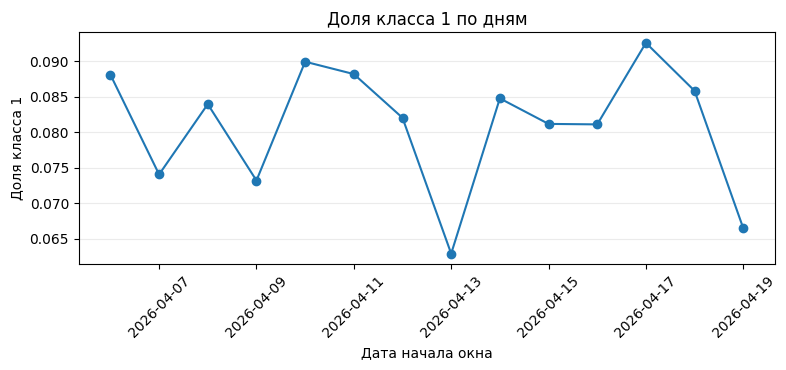

In [4]:
daily = train.groupby(train.window_start_ts.dt.date).target.agg(['size', 'sum', 'mean'])
print(daily.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(pd.to_datetime(daily.index), daily['mean'], marker='o')
ax.set_title('Доля класса 1 по дням')
ax.set_xlabel('Дата начала окна')
ax.set_ylabel('Доля класса 1')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=.25)
fig.tight_layout()
plt.show()

Обучающая выборка заканчивается 19 апреля, а тестовая начинается 20 апреля, поэтому случайное перемешивание здесь не подходит. Проверка качества дальше идет только вперед по времени.

## Допустимые события

Для каждой куки оставляем события не раньше начала окна и строго раньше его окончания. События после окна нельзя использовать даже в обучающей выборке.

In [5]:
meta = pd.concat([train.drop(columns='target'), test], ignore_index=True)
assert meta.cookie_id.is_unique

event_meta = events.merge(
    meta[['cookie_id', 'window_start_ts', 'window_end_ts']],
    on='cookie_id',
    validate='many_to_one',
)

# Оставляем только события внутри окна наблюдения каждой куки
before = event_meta.event_ts.lt(event_meta.window_start_ts)
after = event_meta.event_ts.ge(event_meta.window_end_ts)
inside_mask = ~before & ~after
inside = event_meta.loc[inside_mask].copy()

print('Событий до окна', int(before.sum()))
print('Событий внутри окна', int(inside_mask.sum()))
print('Событий после окна', int(after.sum()))
print('Полных дубликатов', int(inside[events.columns].duplicated().sum()))
print('Показов капчи внутри окна', int(inside.event_name.eq('captcha_shown').sum()))
print('Куки без событий', len(set(meta.cookie_id) - set(inside.cookie_id)))


Событий до окна 0
Событий внутри окна 288126
Событий после окна 40779
Полных дубликатов 4293
Показов капчи внутри окна 0
Куки без событий 0


In [6]:
print('Типы событий внутри окна')
print(inside.event_name.value_counts().to_string())
print()
print('События на одну куки')
print(
    inside.groupby('cookie_id').size()
    .quantile([0, .1, .5, .9, .99, 1])
    .to_string()
)

Типы событий внутри окна
event_name
item_view               108086
search_results_view      89798
photo_swipe              33084
favorite_add             17296
seller_page_view         15542
contact_phone_show       10288
login                     5661
contact_chat_open         5548
contact_message_sent      2823

События на одну куки
0.00      1.0
0.10      3.0
0.50     12.0
0.90     40.0
0.99     89.0
1.00    191.0


После окончания окна есть 40 779 событий. Внутри окна показов капчи нет. Все признаки строим только по событиям внутри окна, чтобы не использовать информацию из будущего.

## Подготовка событий

Нормализуем платформу и считаем признаки между соседними событиями одной куки. Для первого события интервала нет, поэтому доли по интервалам считаются только среди существующих интервалов.

In [7]:
def prepare_events(frame):
    ev = frame.sort_values(['cookie_id', 'event_ts'], kind='mergesort').copy()
    ev['platform_norm'] = ev.platform.str.lower().replace({'iphone': 'ios'})

    ua = ev.user_agent.fillna('')
    ev['headless'] = ua.str.contains(
        'Headless', case=False, regex=False
    ).astype('int8')
    ev['browser_bot'] = ua.str.contains(
        'bot|spider|crawler', case=False, regex=True
    ).astype('int8')

    ev['event_hour'] = ev.event_ts.dt.hour
    ev['event_minute'] = ev.event_ts.dt.floor('min')
    ev['event_second'] = ev.event_ts.dt.floor('s')

    # Считаем интервалы и предыдущие действия только внутри одной куки
    group = ev.groupby('cookie_id', sort=False)
    ev['gap_sec'] = group.event_ts.diff().dt.total_seconds()
    ev['prev_event'] = group.event_name.shift()
    ev['prev_item'] = group.item_id.shift()

    ev['search_to_item'] = (
        (ev.prev_event == 'search_results_view')
        & (ev.event_name == 'item_view')
    ).astype('int8')
    ev['same_item_again'] = (
        ev.item_id.notna() & ev.item_id.eq(ev.prev_item)
    ).astype('int8')
    ev['new_session'] = ev.gap_sec.gt(1800).astype('int8')
    ev['deep_page'] = ev.search_page.ge(5).astype('int8')
    return ev


ev = prepare_events(inside)


## Временные признаки

Кроме среднего интервала добавим квантили и доли коротких интервалов. Такие признаки описывают не только общую скорость, но и форму поведения внутри суток.

In [8]:
for seconds, name in [
    (1, 'gap_le_1'),
    (3, 'gap_le_3'),
    (5, 'gap_le_5'),
    (10, 'gap_le_10'),
    (30, 'gap_le_30'),
    (60, 'gap_le_60'),
]:
    ev[name] = np.where(
        ev.gap_sec.notna(),
        ev.gap_sec.le(seconds).astype(float),
        np.nan,
    )

ev['gap_5_30'] = np.where(
    ev.gap_sec.notna(),
    ev.gap_sec.between(5, 30).astype(float),
    np.nan,
)

## Движение курсора

Чтобы учесть характер взаимодействия с интерфейсом, дополнительно считаем движение между последовательными точками, длину перемещения и скорость. Значения строятся только там, где обе соседние координаты известны.

In [9]:
# Для движения нужны координаты двух соседних событий
group = ev.groupby('cookie_id', sort=False)
ev['prev_x'] = group.pointer_x.shift()
ev['prev_y'] = group.pointer_y.shift()

valid_pointer = (
    ev.pointer_x.notna()
    & ev.pointer_y.notna()
    & ev.prev_x.notna()
    & ev.prev_y.notna()
)

ev['pointer_dx'] = np.where(
    valid_pointer,
    (ev.pointer_x - ev.prev_x).abs(),
    np.nan,
)
ev['pointer_dy'] = np.where(
    valid_pointer,
    (ev.pointer_y - ev.prev_y).abs(),
    np.nan,
)
ev['pointer_dist'] = np.where(
    valid_pointer,
    np.hypot(ev.pointer_x - ev.prev_x, ev.pointer_y - ev.prev_y),
    np.nan,
)
ev['pointer_zero_move'] = np.where(
    valid_pointer,
    ev.pointer_dist.eq(0).astype(float),
    np.nan,
)
ev['pointer_axis_move'] = np.where(
    valid_pointer,
    ((ev.pointer_dx == 0) | (ev.pointer_dy == 0)).astype(float),
    np.nan,
)
ev['pointer_speed'] = np.where(
    valid_pointer & ev.gap_sec.gt(0),
    ev.pointer_dist / ev.gap_sec,
    np.nan,
)


## Основные агрегаты

Собираем счетчики активности, разнообразие объектов, временные характеристики и признаки курсора. Число сессий равно числу пауз больше 30 минут + первая сессия.

In [10]:
def aggregate_numeric(ev):
    group = ev.groupby('cookie_id', sort=False)
    features = group.agg(
        n_events=('eid', 'size'),
        n_types=('event_name', 'nunique'),
        n_items=('item_id', 'nunique'),
        n_categories=('item_category', 'nunique'),
        n_locations=('item_location', 'nunique'),
        n_queries=('search_query', 'nunique'),
        n_pages=('search_page', 'nunique'),
        n_platforms=('platform_norm', 'nunique'),
        n_agents=('user_agent', 'nunique'),
        active_hours=('event_hour', 'nunique'),
        first_event=('event_ts', 'min'),
        last_event=('event_ts', 'max'),
        gap_mean=('gap_sec', 'mean'),
        gap_median=('gap_sec', 'median'),
        gap_std=('gap_sec', 'std'),
        gap_min=('gap_sec', 'min'),
        gap_max=('gap_sec', 'max'),
        gap_p10=('gap_sec', lambda s: s.quantile(.10)),
        gap_p25=('gap_sec', lambda s: s.quantile(.25)),
        gap_p75=('gap_sec', lambda s: s.quantile(.75)),
        gap_p90=('gap_sec', lambda s: s.quantile(.90)),
        gap_le_1_share=('gap_le_1', 'mean'),
        gap_le_3_share=('gap_le_3', 'mean'),
        gap_le_5_share=('gap_le_5', 'mean'),
        gap_le_10_share=('gap_le_10', 'mean'),
        gap_le_30_share=('gap_le_30', 'mean'),
        gap_le_60_share=('gap_le_60', 'mean'),
        regular_gap_share=('gap_5_30', 'mean'),
        n_breaks=('new_session', 'sum'),
        search_to_item=('search_to_item', 'sum'),
        same_item_again=('same_item_again', 'sum'),
        max_search_page=('search_page', 'max'),
        mean_search_page=('search_page', 'mean'),
        n_deep_pages=('deep_page', 'sum'),
        pointer_x_std=('pointer_x', 'std'),
        pointer_y_std=('pointer_y', 'std'),
        pointer_x_min=('pointer_x', 'min'),
        pointer_x_max=('pointer_x', 'max'),
        pointer_y_min=('pointer_y', 'min'),
        pointer_y_max=('pointer_y', 'max'),
        n_pointer_x=('pointer_x', 'nunique'),
        n_pointer_y=('pointer_y', 'nunique'),
        pointer_share=('pointer_x', lambda s: s.notna().mean()),
        pointer_dx_mean=('pointer_dx', 'mean'),
        pointer_dx_median=('pointer_dx', 'median'),
        pointer_dx_p90=('pointer_dx', lambda s: s.quantile(.90)),
        pointer_dy_mean=('pointer_dy', 'mean'),
        pointer_dy_median=('pointer_dy', 'median'),
        pointer_dy_p90=('pointer_dy', lambda s: s.quantile(.90)),
        pointer_dist_mean=('pointer_dist', 'mean'),
        pointer_dist_median=('pointer_dist', 'median'),
        pointer_dist_p90=('pointer_dist', lambda s: s.quantile(.90)),
        pointer_dist_max=('pointer_dist', 'max'),
        pointer_zero_share=('pointer_zero_move', 'mean'),
        pointer_axis_share=('pointer_axis_move', 'mean'),
        pointer_speed_median=('pointer_speed', 'median'),
        pointer_speed_p90=('pointer_speed', lambda s: s.quantile(.90)),
        headless_share=('headless', 'mean'),
        browser_bot_share=('browser_bot', 'mean'),
    )

    features['n_sessions'] = features.n_breaks + 1
    features['pointer_x_range'] = (
        features.pointer_x_max - features.pointer_x_min
    )
    features['pointer_y_range'] = (
        features.pointer_y_max - features.pointer_y_min
    )
    features['span_sec'] = (
        features.last_event - features.first_event
    ).dt.total_seconds()
    features['first_hour'] = features.first_event.dt.hour
    features['last_hour'] = features.last_event.dt.hour
    return features.drop(columns=['first_event', 'last_event'])


features = aggregate_numeric(ev)
print('Кук с агрегатами', len(features))

Кук с агрегатами 16000


## Доли действий

Абсолютные счетчики зависят от общей активности, поэтому для типов событий, платформ и продавцов добавим и количество, и долю от всех событий куки.

In [11]:
for column, prefix in [
    ('event_name', 'event'),
    ('platform_norm', 'platform'),
    ('seller_type', 'seller'),
]:
    counts = pd.crosstab(ev.cookie_id, ev[column])
    counts.columns = [f'{prefix}_{name}' for name in counts.columns]
    features = features.join(counts, how='left')
    for name in counts.columns:
        features[name + '_share'] = features[name] / features.n_events

for column, suffix in {
    'item_id': 'items',
    'item_category': 'categories',
    'item_location': 'locations',
    'search_query': 'queries',
}.items():
    features[column + '_diversity'] = (
        features['n_' + suffix] / features.n_events
    )

In [12]:
for column, name in [
    ('event_minute', 'max_events_minute'),
    ('event_second', 'max_events_second'),
]:
    features[name] = (
        ev.groupby(['cookie_id', column], sort=False)
        .size()
        .groupby(level=0)
        .max()
    )

hour_counts = pd.crosstab(ev.cookie_id, ev.event_hour)
hour_prob = hour_counts.div(hour_counts.sum(axis=1), axis=0)
features['hour_entropy'] = -(
    hour_prob.replace(0, np.nan)
    * np.log(hour_prob.replace(0, np.nan))
).sum(axis=1)

features['events_per_active_minute'] = (
    features.n_events / (features.span_sec / 60 + 1)
)
features['gap_cv'] = features.gap_std / (features.gap_mean + 1)
features['items_per_view'] = (
    features.n_items / (features.event_item_view + 1)
)
features['contacts_per_view'] = (
    features.event_contact_phone_show
    + features.event_contact_chat_open
    + features.event_contact_message_sent
) / (features.event_item_view + 1)
features['search_per_view'] = (
    features.event_search_results_view / (features.event_item_view + 1)
)

## Таблица признаков

Возраст куки известен к моменту окончания окна. После объединения заменяем отсутствующие агрегаты на −1. Это относится, например, к интервалам у куки с одним событием.

In [13]:
result = meta[
    ['cookie_id', 'cookie_created_at', 'window_start_ts', 'window_end_ts']
].copy()
result['cookie_age_days'] = (
    result.window_end_ts - result.cookie_created_at
).dt.total_seconds() / 86400
result['created_hour'] = result.cookie_created_at.dt.hour

result = result[
    ['cookie_id', 'cookie_age_days', 'created_hour']
].merge(
    features.reset_index(),
    on='cookie_id',
    how='left',
    validate='one_to_one',
)

X = (
    result.drop(columns='cookie_id')
    .replace([np.inf, -np.inf], np.nan)
    .fillna(-1)
    .astype('float32')
)
X_train = X.iloc[:len(train)].reset_index(drop=True)
X_test = X.iloc[len(train):].reset_index(drop=True)
y = train.target.to_numpy()

assert X_train.shape[0] == len(train)
assert X_test.shape[0] == len(test)
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
print('Число признаков', X_train.shape[1])

Число признаков 107


## Различия между классами

Для понимания посмотрим на несколько признаков, которые легко интерпретировать. Для курсора отдельно сравним долю событий с координатами и характеристики движения там, где их можно посчитать.

In [14]:
key_features = [
    'n_events',
    'n_items',
    'max_search_page',
    'gap_median',
    'gap_p10',
    'pointer_share',
]

print('Медианы по классам')
print(
    X_train[key_features]
    .groupby(train.target)
    .median()
    .round(2)
    .to_string()
)

# Движение можно посчитать только для куки с несколькими координатами
has_pointer = X_train.pointer_share.gt(0)
has_pointer_move = X_train.pointer_dist_median.ge(0)

print()
print('Доля куки с координатами курсора')
print(
    has_pointer.groupby(train.target)
    .mean()
    .round(3)
    .to_string()
)

print()
print('Медианы движения при наличии последовательных координат')
print(
    X_train.loc[
        has_pointer_move,
        ['pointer_x_std', 'pointer_dist_median', 'pointer_speed_median'],
    ]
    .groupby(train.target[has_pointer_move])
    .median()
    .round(2)
    .to_string()
)


Медианы по классам
        n_events  n_items  max_search_page  gap_median  gap_p10  pointer_share
target                                                                        
0           12.0      6.0              3.0        57.5     14.8            0.0
1           20.0     10.0              7.0        24.0      8.4            0.0

Доля куки с координатами курсора
target
0    0.372
1    0.279

Медианы движения при наличии последовательных координат
        pointer_x_std  pointer_dist_median  pointer_speed_median
target                                                          
0          552.020020           747.010010                 11.76
1          201.850006           352.329987                 10.68


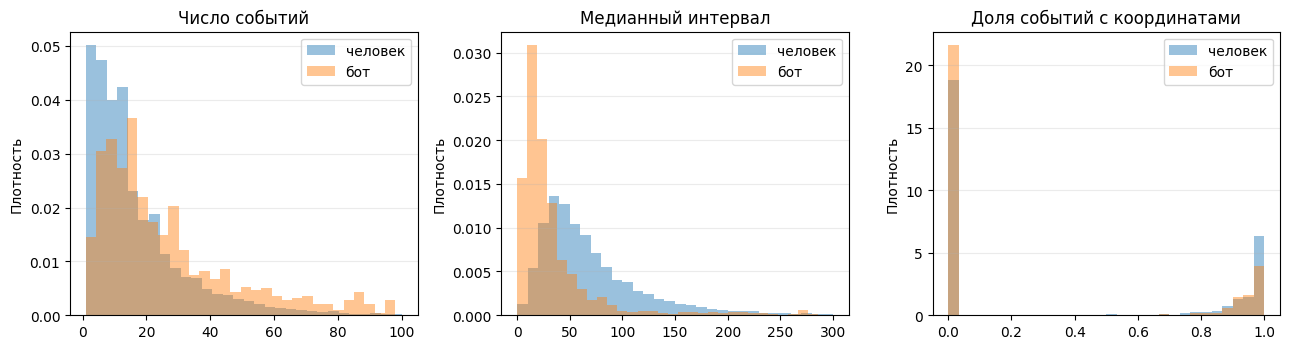

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
plot_specs = [
    ('n_events', 100, 'Число событий'),
    ('gap_median', 300, 'Медианный интервал'),
    ('pointer_share', 1, 'Доля событий с координатами'),
]

for ax, (column, limit, title) in zip(axes, plot_specs):
    for target, label in [(0, 'человек'), (1, 'бот')]:
        values = X_train.loc[train.target.eq(target), column]
        values = values[(values >= 0) & (values <= limit)]
        ax.hist(values, bins=30, density=True, alpha=.45, label=label)
    ax.set_title(title)
    ax.set_ylabel('Плотность')
    ax.legend()
    ax.grid(axis='y', alpha=.25)

fig.tight_layout()
plt.show()


Классы заметно пересекаются, поэтому одного счетчика активности недостаточно. Отличия видны одновременно в скорости действий, разнообразии объектов и использовании курсора. Эти группы признаков имеет смысл проверять вместе.

## Временная проверка качества

Используем пять последовательных проверочных периодов по два дня. Для каждого периода модель обучается только на более ранних датах. Дополнительно оцениваем модель на периоде 13–19 апреля, который по длительности совпадает с тестовой выборкой.

In [16]:
assert precision_at_recall([1, 0, 1, 1, 1], [5, 4, 3, 2, 1]) == 0.8
assert precision_at_recall([1, 1, 0, 0], [0.5] * 4) == 0.5
assert precision_at_recall([0, 0, 1, 1], [0.5] * 4) == 0.5

fold_specs = [
    ('10 и 11 апреля', '2026-04-10', '2026-04-11'),
    ('12 и 13 апреля', '2026-04-12', '2026-04-13'),
    ('14 и 15 апреля', '2026-04-14', '2026-04-15'),
    ('16 и 17 апреля', '2026-04-16', '2026-04-17'),
    ('18 и 19 апреля', '2026-04-18', '2026-04-19'),
]

# Обучение всегда идет на датах раньше проверочного периода
folds = []
for name, start, end in fold_specs:
    fit_mask = train.window_start_ts.lt(start).to_numpy()
    val_mask = train.window_start_ts.between(start, end).to_numpy()
    folds.append((name, fit_mask, val_mask))
    print(
        name,
        'обучение', fit_mask.sum(),
        'проверка', val_mask.sum(),
        'ботов', y[val_mask].sum(),
    )

10 и 11 апреля обучение 3305 проверка 1808 ботов 161
12 и 13 апреля обучение 5113 проверка 1660 ботов 120
14 и 15 апреля обучение 6773 проверка 1627 ботов 135
16 и 17 апреля обучение 8400 проверка 1453 ботов 126
18 и 19 апреля обучение 9853 проверка 1238 ботов 94


## Проверка групп признаков

Сначала проверим, что усложнение признаков действительно дает прирост. Базовый набор соответствует прежним счетчикам и агрегатам. Затем отдельно добавим движение курсора и более подробное распределение интервалов.

In [17]:
pointer_extra = {
    'pointer_dx_mean', 'pointer_dx_median', 'pointer_dx_p90',
    'pointer_dy_mean', 'pointer_dy_median', 'pointer_dy_p90',
    'pointer_dist_mean', 'pointer_dist_median', 'pointer_dist_p90',
    'pointer_dist_max', 'pointer_zero_share', 'pointer_axis_share',
    'pointer_speed_median', 'pointer_speed_p90',
    'pointer_x_min', 'pointer_x_max', 'pointer_y_min', 'pointer_y_max',
    'pointer_x_range', 'pointer_y_range',
}
gap_extra = {
    'gap_p25', 'gap_p75',
    'gap_le_1_share', 'gap_le_3_share', 'gap_le_5_share',
    'gap_le_10_share', 'gap_le_30_share', 'gap_le_60_share',
}

base_columns = [
    column for column in X_train.columns
    if column not in pointer_extra | gap_extra
]
pointer_columns = base_columns + sorted(pointer_extra)
best_columns = pointer_columns + sorted(gap_extra)

feature_sets = {
    'Базовые признаки': base_columns,
    'Добавили движение курсора': pointer_columns,
    'Добавили интервалы': best_columns,
}
print({name: len(columns) for name, columns in feature_sets.items()})

{'Базовые признаки': 79, 'Добавили движение курсора': 99, 'Добавили интервалы': 107}


In [18]:
def make_catboost(depth=6, iterations=250):
    return CatBoostClassifier(
        iterations=iterations,
        depth=depth,
        learning_rate=.06 if iterations <= 250 else .05,
        l2_leaf_reg=5,
        loss_function='Logloss',
        verbose=False,
        thread_count=8,
        random_seed=SEED,
        allow_writing_files=False,
    )

# Сравниваем группы признаков на одинаковых временных разбиениях
ablation_folds = folds[-3:]
ablation_rows = []
for set_name, columns in feature_sets.items():
    for fold_name, fit_mask, val_mask in ablation_folds:
        model = make_catboost(depth=6, iterations=250)
        model.fit(X_train.loc[fit_mask, columns], y[fit_mask])
        score = model.predict_proba(
            X_train.loc[val_mask, columns]
        )[:, 1]
        ablation_rows.append({
            'Признаки': set_name,
            'Период': fold_name,
            'P@R≥0.70': precision_at_recall(y[val_mask], score),
        })

ablation = pd.DataFrame(ablation_rows)
print(
    ablation.pivot(
        index='Признаки', columns='Период', values='P@R≥0.70'
    ).round(4).to_string()
)
print()
print('Среднее')
print(
    ablation.groupby('Признаки')['P@R≥0.70']
    .mean()
    .sort_values(ascending=False)
    .round(4)
    .to_string()
)

Период                     14 и 15 апреля  16 и 17 апреля  18 и 19 апреля
Признаки                                                                 
Базовые признаки                   0.6400          0.6953          0.7053
Добавили движение курсора          0.6985          0.7895          0.6979
Добавили интервалы                 0.7007          0.7739          0.7253

Среднее
Признаки
Добавили интервалы           0.7333
Добавили движение курсора    0.7286
Базовые признаки             0.6802


Движение курсора дает заметный прирост относительно базового набора. Дополнительные квантили и доли интервалов дают небольшой дополнительный прирост в среднем, хотя эффект меняется между периодами. Поэтому дальше используем набор с признаками движения курсора и расширенными признаками интервалов.

## Проверка дубликатов

Полностью одинаковые строки могут означать повторившиеся действия, поэтому удалять их автоматически нельзя. Проверим оба варианта на двух последних периодах.

In [19]:
deduplicated = inside.drop_duplicates(subset=events.columns.tolist()).copy()
print('Удалено строк', len(inside) - len(deduplicated))

Удалено строк 4293


In [20]:
def build_feature_matrix(frame):
    prepared = prepare_events(frame)

    for seconds, name in [
        (1, 'gap_le_1'), (3, 'gap_le_3'), (5, 'gap_le_5'),
        (10, 'gap_le_10'), (30, 'gap_le_30'), (60, 'gap_le_60'),
    ]:
        prepared[name] = np.where(
            prepared.gap_sec.notna(),
            prepared.gap_sec.le(seconds).astype(float),
            np.nan,
        )
    prepared['gap_5_30'] = np.where(
        prepared.gap_sec.notna(),
        prepared.gap_sec.between(5, 30).astype(float),
        np.nan,
    )

    group = prepared.groupby('cookie_id', sort=False)
    prepared['prev_x'] = group.pointer_x.shift()
    prepared['prev_y'] = group.pointer_y.shift()
    valid = (
        prepared.pointer_x.notna()
        & prepared.pointer_y.notna()
        & prepared.prev_x.notna()
        & prepared.prev_y.notna()
    )
    prepared['pointer_dx'] = np.where(
        valid, (prepared.pointer_x - prepared.prev_x).abs(), np.nan
    )
    prepared['pointer_dy'] = np.where(
        valid, (prepared.pointer_y - prepared.prev_y).abs(), np.nan
    )
    prepared['pointer_dist'] = np.where(
        valid,
        np.hypot(
            prepared.pointer_x - prepared.prev_x,
            prepared.pointer_y - prepared.prev_y,
        ),
        np.nan,
    )
    prepared['pointer_zero_move'] = np.where(
        valid, prepared.pointer_dist.eq(0).astype(float), np.nan
    )
    prepared['pointer_axis_move'] = np.where(
        valid,
        ((prepared.pointer_dx == 0) | (prepared.pointer_dy == 0)).astype(float),
        np.nan,
    )
    prepared['pointer_speed'] = np.where(
        valid & prepared.gap_sec.gt(0),
        prepared.pointer_dist / prepared.gap_sec,
        np.nan,
    )

    table = aggregate_numeric(prepared)
    for column, prefix in [
        ('event_name', 'event'),
        ('platform_norm', 'platform'),
        ('seller_type', 'seller'),
    ]:
        counts = pd.crosstab(prepared.cookie_id, prepared[column])
        counts.columns = [f'{prefix}_{name}' for name in counts.columns]
        table = table.join(counts, how='left')
        for name in counts.columns:
            table[name + '_share'] = table[name] / table.n_events

    for column, suffix in {
        'item_id': 'items',
        'item_category': 'categories',
        'item_location': 'locations',
        'search_query': 'queries',
    }.items():
        table[column + '_diversity'] = table['n_' + suffix] / table.n_events

    for column, name in [
        ('event_minute', 'max_events_minute'),
        ('event_second', 'max_events_second'),
    ]:
        table[name] = (
            prepared.groupby(['cookie_id', column], sort=False)
            .size().groupby(level=0).max()
        )

    hour_counts = pd.crosstab(prepared.cookie_id, prepared.event_hour)
    hour_prob = hour_counts.div(hour_counts.sum(axis=1), axis=0)
    table['hour_entropy'] = -(
        hour_prob.replace(0, np.nan)
        * np.log(hour_prob.replace(0, np.nan))
    ).sum(axis=1)
    table['events_per_active_minute'] = (
        table.n_events / (table.span_sec / 60 + 1)
    )
    table['gap_cv'] = table.gap_std / (table.gap_mean + 1)
    table['items_per_view'] = table.n_items / (table.event_item_view + 1)
    table['contacts_per_view'] = (
        table.event_contact_phone_show
        + table.event_contact_chat_open
        + table.event_contact_message_sent
    ) / (table.event_item_view + 1)
    table['search_per_view'] = (
        table.event_search_results_view / (table.event_item_view + 1)
    )

    combined = result[['cookie_id', 'cookie_age_days', 'created_hour']].merge(
        table.reset_index(),
        on='cookie_id',
        how='left',
        validate='one_to_one',
    )
    return (
        combined.drop(columns='cookie_id')
        .reindex(columns=X_train.columns)
        .replace([np.inf, -np.inf], np.nan)
        .fillna(-1)
        .astype('float32')
    )

In [21]:
X_dedup = build_feature_matrix(deduplicated)
X_dedup_train = X_dedup.iloc[:len(train)].reset_index(drop=True)

duplicate_rows = []
for label, matrix in [
    ('Оставили дубликаты', X_train),
    ('Удалили дубликаты', X_dedup_train),
]:
    for fold_name, fit_mask, val_mask in folds[-2:]:
        model = make_catboost(depth=6, iterations=350)
        model.fit(matrix.loc[fit_mask, best_columns], y[fit_mask])
        score = model.predict_proba(
            matrix.loc[val_mask, best_columns]
        )[:, 1]
        duplicate_rows.append({
            'Вариант': label,
            'Период': fold_name,
            'P@R≥0.70': precision_at_recall(y[val_mask], score),
        })

print(
    pd.DataFrame(duplicate_rows)
    .pivot(index='Вариант', columns='Период', values='P@R≥0.70')
    .round(4)
    .to_string()
)

Период              16 и 17 апреля  18 и 19 апреля
Вариант                                           
Оставили дубликаты          0.7863          0.7312
Удалили дубликаты           0.8091          0.7204


На двух последних периодах разница небольшая и не дает устойчивого преимущества удалению повторов. Полностью одинаковые строки могут соответствовать повторившимся действиям, поэтому в финальном варианте оставляем исходные события.

## Проверка финальной модели

Для выбранного набора признаков проверяем CatBoost глубины 7 на всех пяти временных разбиениях. Дополнительно проверяем модель на едином семидневном отрезке, поскольку тестовая выборка тоже охватывает семь дней.

In [22]:
def evaluate_model(depth, columns, selected_folds, iterations=400):
    rows = []
    scores = {}
    for fold_name, fit_mask, val_mask in selected_folds:
        model = make_catboost(depth=depth, iterations=iterations)
        model.fit(X_train.loc[fit_mask, columns], y[fit_mask])
        score = model.predict_proba(
            X_train.loc[val_mask, columns]
        )[:, 1]
        scores[fold_name] = score
        rows.append({
            'Модель': f'CatBoost depth {depth}',
            'Период': fold_name,
            'P@R≥0.70': precision_at_recall(y[val_mask], score),
            'PR-AUC': average_precision_score(y[val_mask], score),
            'ROC-AUC': roc_auc_score(y[val_mask], score),
        })
    return pd.DataFrame(rows), scores

results_7, scores_7 = evaluate_model(
    depth=7,
    columns=best_columns,
    selected_folds=folds,
    iterations=400,
)
print(results_7.round(4).to_string(index=False))
print()
print('Среднее', round(results_7['P@R≥0.70'].mean(), 4))
print('Стандартное отклонение', round(results_7['P@R≥0.70'].std(ddof=0), 4))
print('Минимум', round(results_7['P@R≥0.70'].min(), 4))

          Модель         Период  P@R≥0.70  PR-AUC  ROC-AUC
CatBoost depth 7 10 и 11 апреля    0.7847  0.7654   0.9286
CatBoost depth 7 12 и 13 апреля    0.6885  0.7591   0.9268
CatBoost depth 7 14 и 15 апреля    0.7059  0.8031   0.9404
CatBoost depth 7 16 и 17 апреля    0.7876  0.7915   0.9390
CatBoost depth 7 18 и 19 апреля    0.7416  0.7778   0.9374

Среднее 0.7417
Стандартное отклонение 0.0402
Минимум 0.6885


In [23]:
# Дополнительно проверяем модель на едином семидневном периоде
long_fit = train.window_start_ts.lt('2026-04-13').to_numpy()
long_val = train.window_start_ts.ge('2026-04-13').to_numpy()

long_model = make_catboost(depth=7, iterations=400)
long_model.fit(X_train.loc[long_fit, best_columns], y[long_fit])
long_score = long_model.predict_proba(
    X_train.loc[long_val, best_columns]
)[:, 1]

print('Проверка 13–19 апреля')
print('Куки', int(long_val.sum()))
print('Ботов', int(y[long_val].sum()))
print('P@R≥0.70', round(precision_at_recall(y[long_val], long_score), 4))
print('PR-AUC', round(average_precision_score(y[long_val], long_score), 4))
print('ROC-AUC', round(roc_auc_score(y[long_val], long_score), 4))

Проверка 13–19 апреля
Куки 5161
Ботов 408
P@R≥0.70 0.7186
PR-AUC 0.7802
ROC-AUC 0.9374


Пять временных проверок дают более полную картину качества. Результат меняется между периодами. На трёх последних периодах он заметно выше результата простой базовой модели. Семидневный отрезок используем как дополнительную проверку на периоде той же длины, что и тестовая выборка.

## Простая базовая модель

Сравним финальную модель со случайным лесом только по числу событий и числу объявлений.

In [24]:
baseline_rows = []
for fold_name, fit_mask, val_mask in folds[-3:]:
    baseline = RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        n_jobs=-1,
        random_state=SEED,
    )
    baseline.fit(
        X_train.loc[fit_mask, ['n_events', 'n_items']],
        y[fit_mask],
    )
    score = baseline.predict_proba(
        X_train.loc[val_mask, ['n_events', 'n_items']]
    )[:, 1]
    baseline_rows.append({
        'Период': fold_name,
        'P@R≥0.70': precision_at_recall(y[val_mask], score),
    })

baseline_results = pd.DataFrame(baseline_rows)
print(baseline_results.round(4).to_string(index=False))
print('Среднее', round(baseline_results['P@R≥0.70'].mean(), 4))

        Период  P@R≥0.70
14 и 15 апреля    0.1086
16 и 17 апреля    0.1032
18 и 19 апреля    0.1020
Среднее 0.1046


## Ошибки на длинной проверке

Разберем ложные срабатывания и пропуски только на размеченной проверочной части.

In [25]:
def best_threshold(y_true, score, target_recall=.70):
    order = np.argsort(-score, kind='mergesort')
    y_sorted = np.asarray(y_true)[order]
    score_sorted = np.asarray(score)[order]
    ends = np.r_[score_sorted[1:] != score_sorted[:-1], True]
    tp = np.cumsum(y_sorted)[ends]
    count = np.arange(1, len(y_sorted) + 1)[ends]
    precision = tp / count
    recall = tp / y_sorted.sum()
    valid = recall >= target_recall
    best = np.flatnonzero(valid)[np.argmax(precision[valid])]
    thresholds = score_sorted[ends]
    return thresholds[best]

# Порог выбираем только по размеченной проверочной части
threshold = best_threshold(y[long_val], long_score)
long_pred = long_score >= threshold
long_true = y[long_val]

error_table = X_train.loc[
    long_val,
    [
        'n_events', 'gap_median', 'gap_p10',
        'pointer_share', 'n_pointer_x',
        'max_search_page', 'n_categories',
    ],
].copy()
error_table['Группа'] = np.select(
    [
        (long_true == 1) & long_pred,
        (long_true == 0) & long_pred,
        (long_true == 1) & ~long_pred,
    ],
    ['TP', 'FP', 'FN'],
    default='TN',
)

print('Порог', round(float(threshold), 5))
print(error_table['Группа'].value_counts().to_string())
print()
print('Медианы признаков')
print(
    error_table.groupby('Группа')
    .median(numeric_only=True)
    .round(2)
    .to_string()
)

Порог 0.18842
Группа
TN    4641
TP     286
FN     122
FP     112

Медианы признаков
        n_events  gap_median  gap_p10  pointer_share  n_pointer_x  max_search_page  n_categories
Группа                                                                                          
FN          12.5        38.0    12.20            0.0          0.0              4.0           2.0
FP          23.0        22.0     8.05            0.0          0.0              7.0           2.0
TN          12.0        58.0    15.30            0.0          0.0              3.0           2.0
TP          26.0        19.5     7.00            0.0          0.0              8.0           2.0


Ошибки подтверждают, что часть человеческого трафика похожа на автоматизированный по скорости и объему действий, поэтому модель должна учитывать сочетание признаков.

## Итоговое обучение

Финальную модель обучаем на всех размеченных куки. Используем CatBoost глубины 7 и набор признаков, который лучше всего показал себя на временных проверках.

In [26]:
# После выбора модели обучаем ее на всех размеченных данных
final_model = make_catboost(depth=7, iterations=400)
final_model.fit(X_train[best_columns], y)
score_test = final_model.predict_proba(X_test[best_columns])[:, 1]

print('Финальных признаков', len(best_columns))
print('Диапазон score', round(score_test.min(), 6), round(score_test.max(), 6))

Финальных признаков 107
Диапазон score 0.000193 0.99928


## Важные признаки

Важность CatBoost показывает, какие признаки сильнее влияют на предсказания модели.

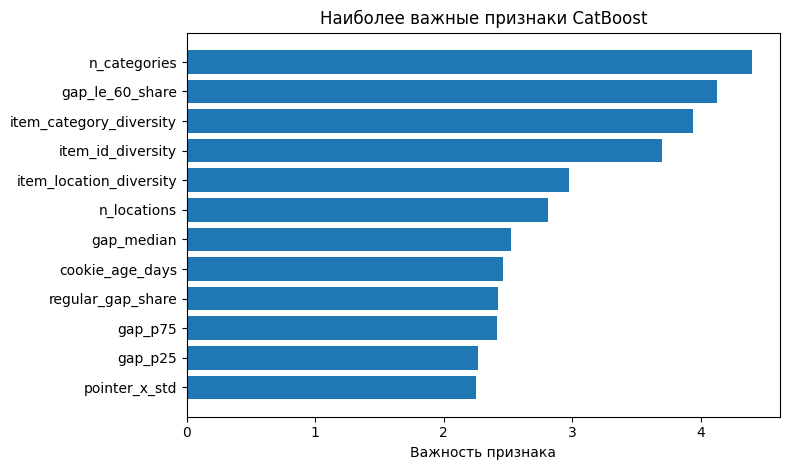

n_categories               4.40
gap_le_60_share            4.13
item_category_diversity    3.94
item_id_diversity          3.70
item_location_diversity    2.97
n_locations                2.81
gap_median                 2.52
cookie_age_days            2.46
regular_gap_share          2.42
gap_p75                    2.41
gap_p25                    2.26
pointer_x_std              2.25


In [27]:
importance = pd.Series(
    final_model.get_feature_importance(),
    index=best_columns,
)
top = importance.nlargest(12).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top.index, top.values)
ax.set_title('Наиболее важные признаки CatBoost')
ax.set_xlabel('Важность признака')
fig.tight_layout()
plt.show()
print(top.sort_values(ascending=False).round(2).to_string())

## Формирование submission

Сохраняем непрерывный score. Порог выбирать не нужно.

In [28]:
submission = pd.DataFrame({
    'cookie_id': test.cookie_id,
    'score': score_test,
})

# Проверяем формат файла перед сохранением
assert submission.columns.tolist() == ['cookie_id', 'score']
assert len(submission) == len(test)
assert submission.cookie_id.is_unique
assert submission.cookie_id.notna().all()
assert submission.score.notna().all()
assert submission.score.between(0, 1).all()
assert set(submission.cookie_id) == set(test.cookie_id)
assert set(submission.cookie_id) == set(sample.cookie_id)

submission.to_csv('submission.csv', index=False)
print('Строк', len(submission))
print('Минимальный score', round(submission.score.min(), 6))
print('Максимальный score', round(submission.score.max(), 6))

Строк 4909
Минимальный score 0.000193
Максимальный score 0.99928


## Вывод

События после окончания окна были исключены до построения признаков. Основной прирост относительно базового набора дали признаки движения курсора. Более подробное описание интервалов между действиями в среднем дало небольшой дополнительный прирост. Дополнительные группы признаков оценивались на временных разбиениях.

На пяти последовательных проверках CatBoost глубины 7 получил среднее P@R около 0.742. На дополнительной семидневной проверке результат составил около 0.719. Качество различается между периодами, поэтому результат на локальной проверке может отличаться от результата на скрытой выборке. Финальная модель обучена на всех размеченных данных с 107 признаками.